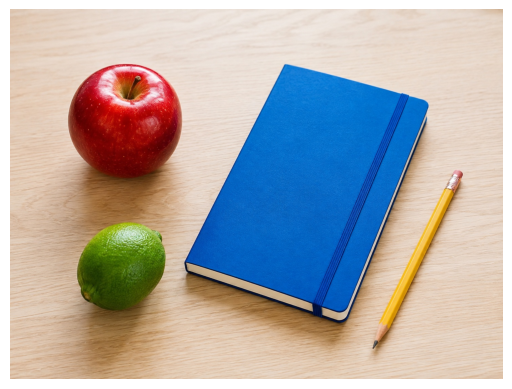

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

obraz = cv2.imread("obraz_testowy.jpg")
obraz_rgb = cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB)
plt.imshow(obraz_rgb)
plt.axis("off")
plt.show()

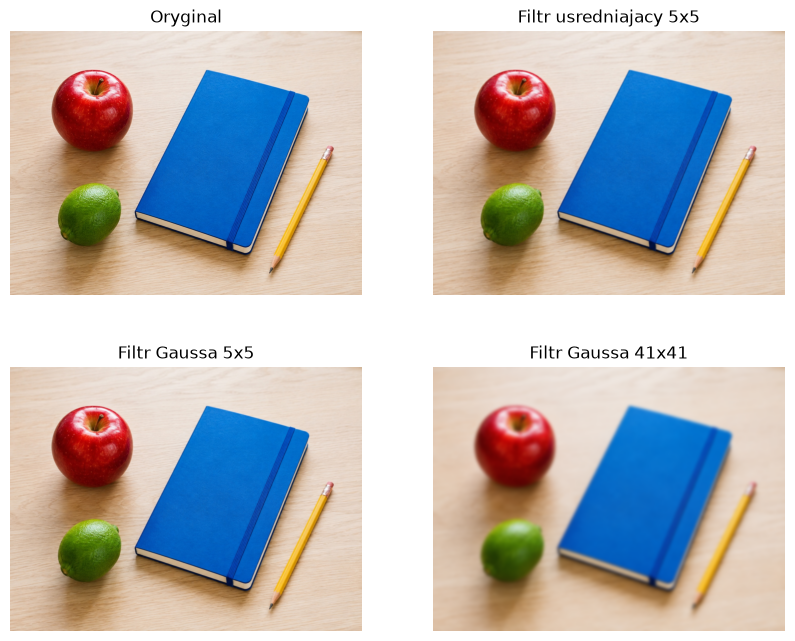

In [3]:
usredniajacy = cv2.blur(obraz_rgb, (5, 5))
gauss_maly = cv2.GaussianBlur(obraz_rgb, (5, 5), 0)
gauss_duzy = cv2.GaussianBlur(obraz_rgb, (41, 41), 0)
plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.imshow(obraz_rgb)
plt.title("Oryginal")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(usredniajacy)
plt.title("Filtr usredniajacy 5x5")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(gauss_maly)
plt.title("Filtr Gaussa 5x5")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(gauss_duzy)
plt.title("Filtr Gaussa 41x41")
plt.axis("off")
plt.show()

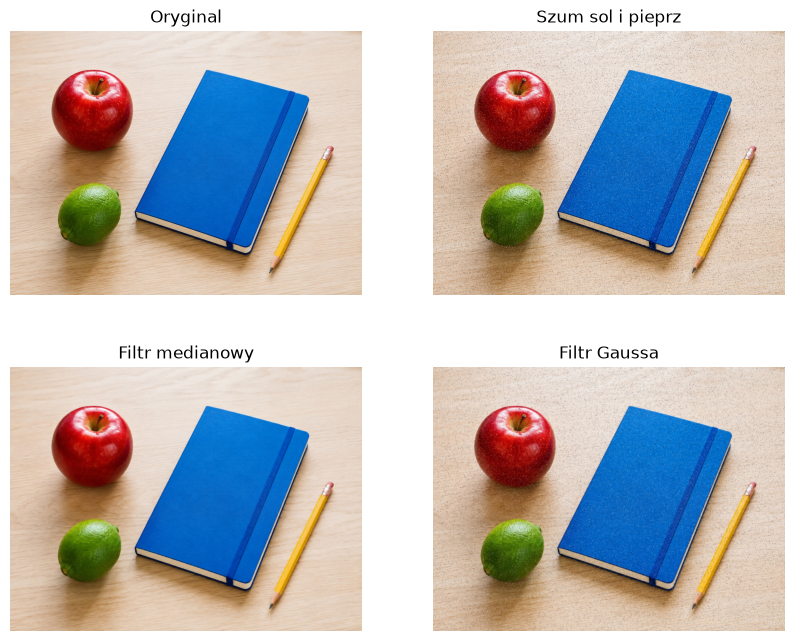

In [4]:
zaszumiony = obraz_rgb.copy()
wys, szer = zaszumiony.shape[:2]
ile = int(0.02 * wys * szer)
ys = np.random.randint(0, wys, ile)
xs = np.random.randint(0, szer, ile)
zaszumiony[ys, xs] = [255, 255, 255]
ys = np.random.randint(0, wys, ile)
xs = np.random.randint(0, szer, ile)
zaszumiony[ys, xs] = [0, 0, 0]

po_medianie = cv2.medianBlur(zaszumiony, 5)
po_gaussie = cv2.GaussianBlur(zaszumiony, (5, 5), 0)
plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.imshow(obraz_rgb)
plt.title("Oryginal")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(zaszumiony)
plt.title("Szum sol i pieprz")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(po_medianie)
plt.title("Filtr medianowy")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(po_gaussie)
plt.title("Filtr Gaussa")
plt.axis("off")
plt.show()

In [5]:
zaszumiony2 = obraz_rgb.copy()
# Proporcja pikseli zakłuconych
probability = 0.02
threshold = 1 - probability
for i in range(obraz_rgb.shape[0]):
    for j in range(obraz_rgb.shape[1]):
        random_val = np.random.random()
        if random_val < probability:  # Noise pixel
            # Losowe wartości RGB
            zaszumiony2[i][j] = [
                np.random.randint(0, 256),
                np.random.randint(0, 256),
                np.random.randint(0, 256),
            ]

Srednia zmiana wartosci piksela: 8.28


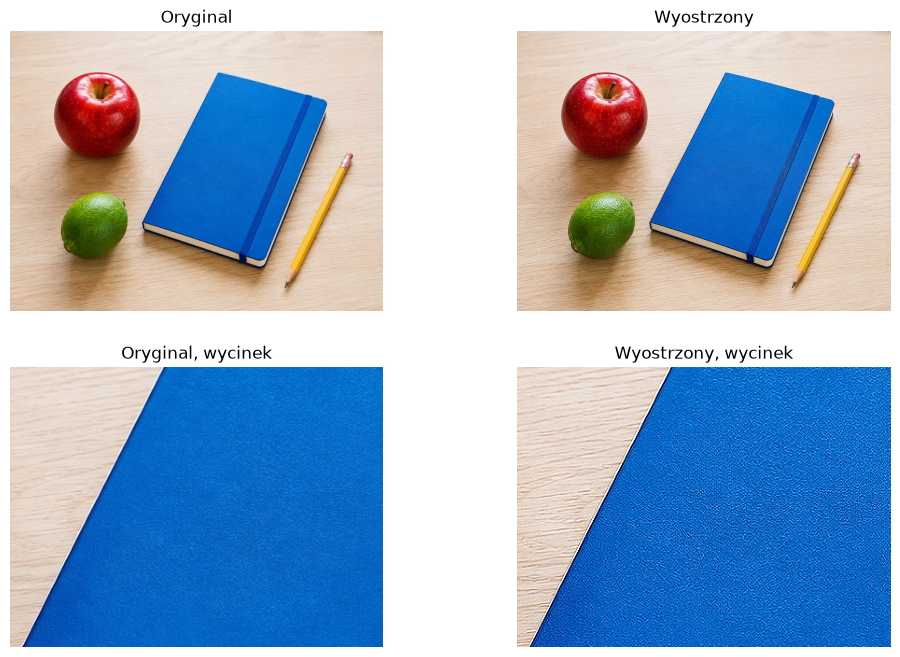

In [6]:
jadro_wyostrzajace = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
wyostrzony = cv2.filter2D(obraz_rgb, -1, jadro_wyostrzajace)
roznica = np.mean(np.abs(wyostrzony.astype(int) - obraz_rgb.astype(int)))
print("Srednia zmiana wartosci piksela:", round(roznica, 2))
sy, sx = obraz_rgb.shape[0] // 2, obraz_rgb.shape[1] // 2
wycinek_o = obraz_rgb[sy - 150 : sy + 150, sx - 200 : sx + 200]
wycinek_w = wyostrzony[sy - 150 : sy + 150, sx - 200 : sx + 200]
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(obraz_rgb)
plt.title("Oryginal")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(wyostrzony)
plt.title("Wyostrzony")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(wycinek_o)
plt.title("Oryginal, wycinek")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(wycinek_w)
plt.title("Wyostrzony, wycinek")
plt.axis("off")
plt.show()

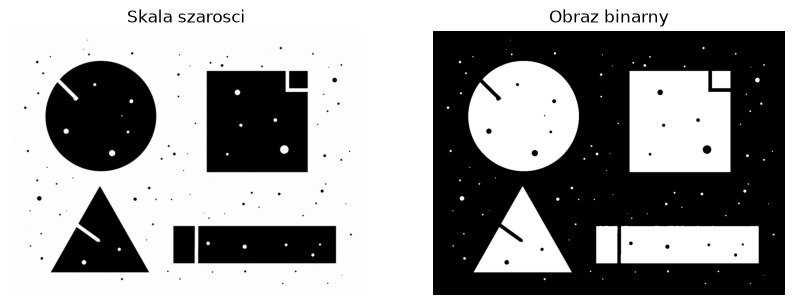

In [7]:
ksztalty = cv2.imread("obraz_ksztalty.jpg")
ksztalty_szare = cv2.cvtColor(ksztalty, cv2.COLOR_BGR2GRAY)
prog, binarny = cv2.threshold(ksztalty_szare, 127, 255, cv2.THRESH_BINARY_INV)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(ksztalty_szare, cmap="gray")
plt.title("Skala szarosci")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(binarny, cmap="gray")
plt.title("Obraz binarny")
plt.axis("off")
plt.show()

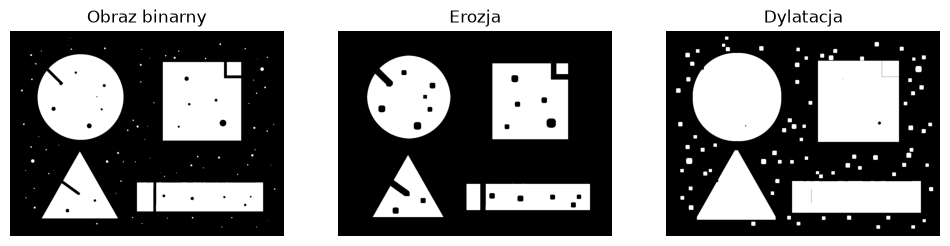

In [8]:
jadro = np.ones((15, 15), np.uint8)
erozja = cv2.erode(binarny, jadro, iterations=1)
dylatacja = cv2.dilate(binarny, jadro, iterations=1)
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(binarny, cmap="gray")
plt.title("Obraz binarny")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(erozja, cmap="gray")
plt.title("Erozja")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(dylatacja, cmap="gray")
plt.title("Dylatacja")
plt.axis("off")
plt.show()

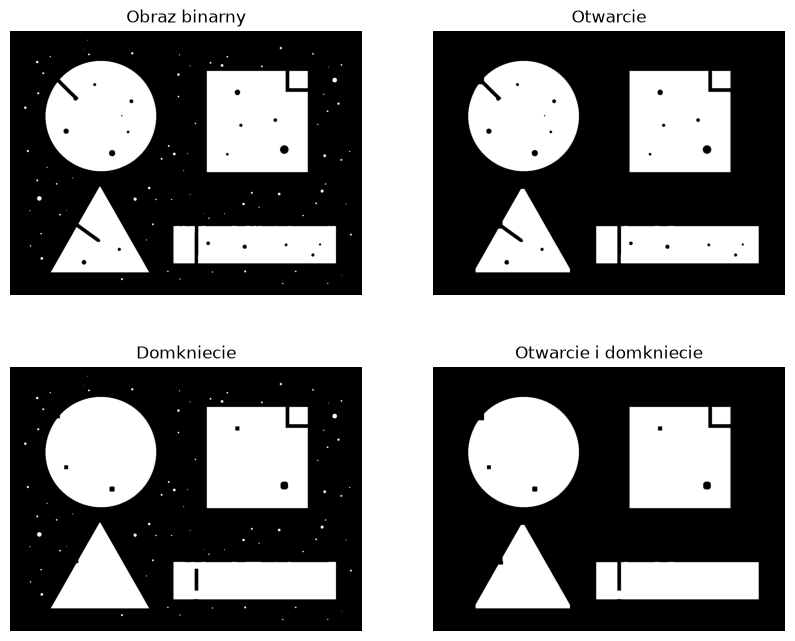

In [9]:
otwarcie = cv2.morphologyEx(binarny, cv2.MORPH_OPEN, jadro)
domkniecie = cv2.morphologyEx(binarny, cv2.MORPH_CLOSE, jadro)
oczyszczony = cv2.morphologyEx(otwarcie, cv2.MORPH_CLOSE, jadro)
plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.imshow(binarny, cmap="gray")
plt.title("Obraz binarny")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(otwarcie, cmap="gray")
plt.title("Otwarcie")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(domkniecie, cmap="gray")
plt.title("Domkniecie")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(oczyszczony, cmap="gray")
plt.title("Otwarcie i domkniecie")
plt.axis("off")
plt.show()

# Zadanie 1

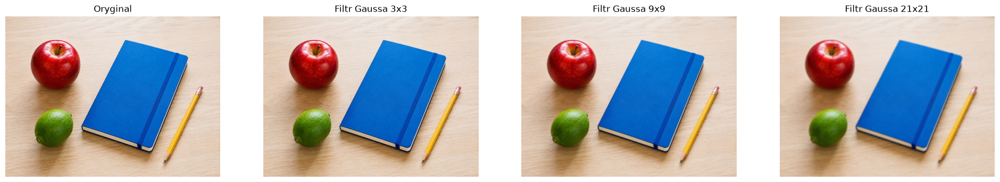

In [10]:
obraz_rgb = cv2.cvtColor(cv2.imread("obraz_testowy.jpg"), cv2.COLOR_BGR2RGB)

gauss_maly = cv2.GaussianBlur(obraz_rgb, (3, 3), 0)
gauss_sredni = cv2.GaussianBlur(obraz_rgb, (9, 9), 0)
gauss_duzy = cv2.GaussianBlur(obraz_rgb, (21, 21), 0)
plt.figure(figsize=(24, 10))
plt.subplot(1, 4, 1)
plt.imshow(obraz_rgb)
plt.title("Oryginal")
plt.axis("off")
plt.subplot(1, 4, 2)
plt.imshow(gauss_maly)
plt.title("Filtr Gaussa 3x3")
plt.axis("off")
plt.subplot(1, 4, 3)
plt.imshow(gauss_sredni)
plt.title("Filtr Gaussa 9x9")
plt.axis("off")
plt.subplot(1, 4, 4)
plt.imshow(gauss_duzy)
plt.title("Filtr Gaussa 21x21")
plt.axis("off")
plt.show()

Im większy rozmiar, tym bardziej rozmyty jest obraz

# Zadanie 2

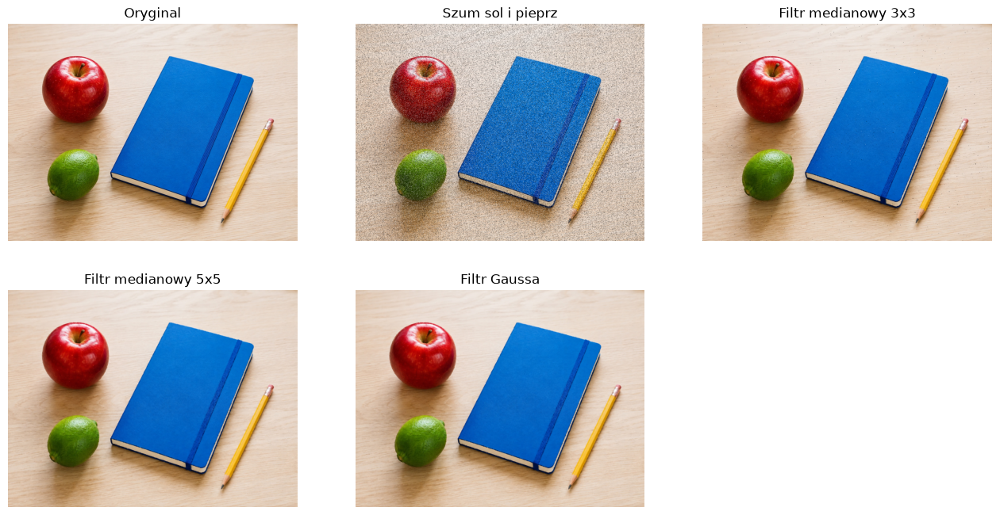

In [17]:
obraz_rgb = cv2.cvtColor(cv2.imread("obraz_testowy.jpg"), cv2.COLOR_BGR2RGB)

zaszumiony = obraz_rgb.copy()
wys, szer = zaszumiony.shape[:2]
ile = int(0.1 * wys * szer)
ys = np.random.randint(0, wys, ile)
xs = np.random.randint(0, szer, ile)
zaszumiony[ys, xs] = [255, 255, 255]
ys = np.random.randint(0, wys, ile)
xs = np.random.randint(0, szer, ile)
zaszumiony[ys, xs] = [0, 0, 0]

po_medianie_3 = cv2.medianBlur(zaszumiony, 3)
po_medianie_5 = cv2.medianBlur(zaszumiony, 5)
po_gaussie = cv2.GaussianBlur(zaszumiony, (5, 5), 0)

plt.figure(figsize=(16, 8))
plt.subplot(2, 3, 1)
plt.imshow(obraz_rgb)
plt.title("Oryginal")
plt.axis("off")
plt.subplot(2, 3, 2)
plt.imshow(zaszumiony)
plt.title("Szum sol i pieprz")
plt.axis("off")
plt.subplot(2, 3, 3)
plt.imshow(po_medianie_3)
plt.title("Filtr medianowy 3x3")
plt.axis("off")
plt.subplot(2, 3, 4)
plt.imshow(po_medianie_5)
plt.title("Filtr medianowy 5x5")
plt.axis("off")
plt.subplot(2, 3, 5)
plt.imshow(po_medianie_5)
plt.title("Filtr Gaussa")
plt.axis("off")
plt.show()

Najlepszy filtr to medianowy 5x5, jest najbardziej przejrzysty. Filtr Gaussa wydaje się być rozmyty, natomiast filtr 3x3 nie wyeliminował wszystkiego. 

# Zadanie 3

(np.float64(-0.5), np.float64(1447.5), np.float64(1085.5), np.float64(-0.5))

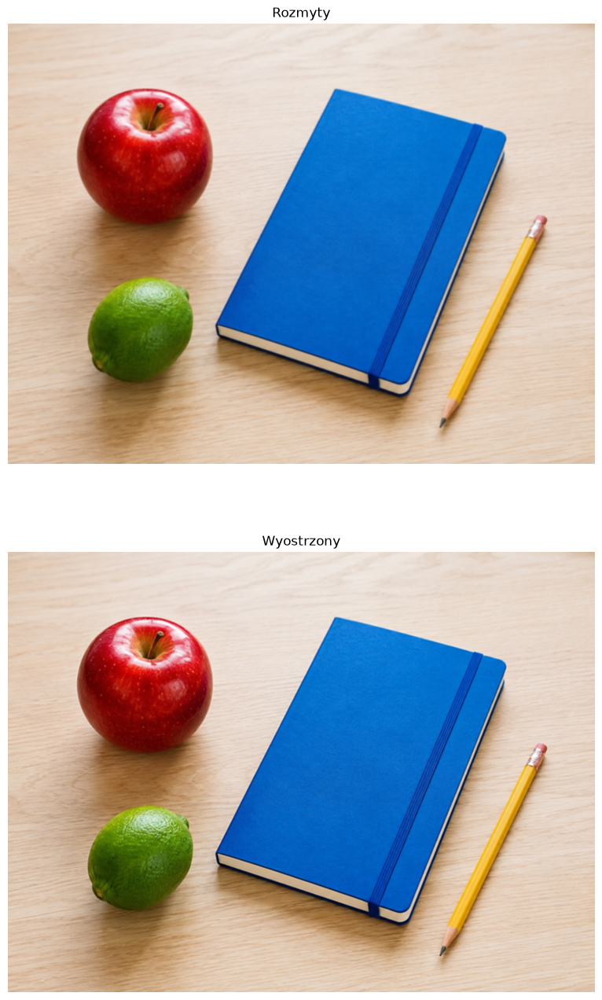

In [18]:
obraz_rgb = cv2.cvtColor(cv2.imread("obraz_testowy.jpg"), cv2.COLOR_BGR2RGB)

rozmyty = cv2.GaussianBlur(obraz_rgb, (7, 7), 0)

jadro_wyostrzajace = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
wyostrzony = cv2.filter2D(rozmyty, -1, jadro_wyostrzajace)

plt.figure(figsize=(16, 16))
plt.subplot(2, 1, 1)
plt.imshow(rozmyty)
plt.title("Rozmyty")
plt.axis("off")
plt.subplot(2, 1, 2)
plt.imshow(wyostrzony)
plt.title("Wyostrzony")
plt.axis("off")

Tak, wyostrzenie obrazu pomogło. Nie widać utraty szczegółów.

# Zadanie 4

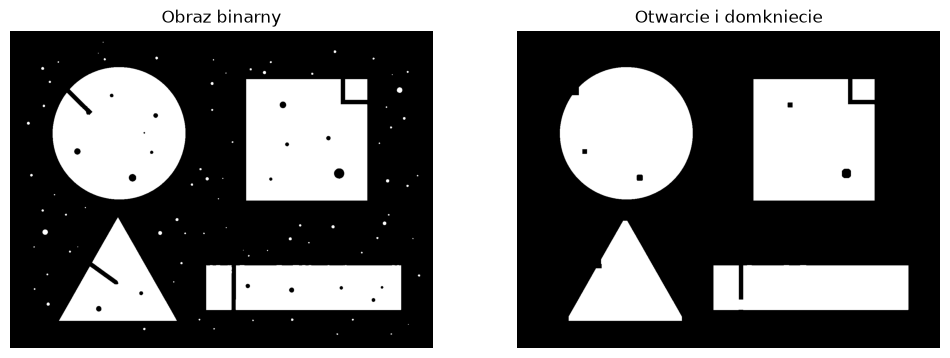

In [13]:
ksztalty = cv2.cvtColor(cv2.imread("obraz_ksztalty.jpg"), cv2.COLOR_BGR2GRAY)
prog, binarny = cv2.threshold(ksztalty, 127, 255, cv2.THRESH_BINARY_INV)

otwarcie = cv2.morphologyEx(binarny, cv2.MORPH_OPEN, jadro)
oczyszczony = cv2.morphologyEx(otwarcie, cv2.MORPH_CLOSE, jadro)

plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1)
plt.imshow(binarny, cmap="gray")
plt.title("Obraz binarny")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(oczyszczony, cmap="gray")
plt.title("Otwarcie i domkniecie")
plt.axis("off")
plt.show()

Najlepszy efekt dostałem, wykorzystując najpierw MORPH_OPEN i potem MORPH_CLOSE

# Zadanie 5

Próg ręczny: 127.0
Próg wyznaczony metodą Otsu: 146.0


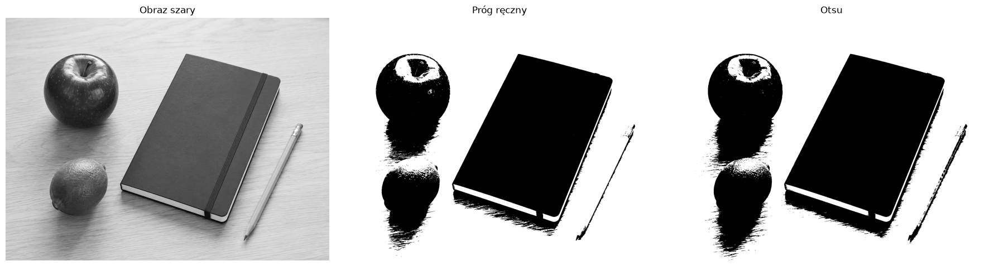

In [14]:
szary = cv2.cvtColor(cv2.imread("obraz_testowy.jpg"), cv2.COLOR_BGR2GRAY)

prog, binarny = cv2.threshold(szary, 127, 255, cv2.THRESH_BINARY)

prog_otsu, binarny_otsu = cv2.threshold(
    szary, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print(f"Próg ręczny: {prog}")
print(f"Próg wyznaczony metodą Otsu: {prog_otsu}")

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(szary, cmap="gray")
plt.title("Obraz szary")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binarny, cmap="gray")
plt.title("Próg ręczny")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(binarny_otsu, cmap="gray")
plt.title("Otsu")
plt.axis("off")

plt.tight_layout()
plt.show()

OTSU lepiej oddzielił cienie

# Zadanie dodatkowe

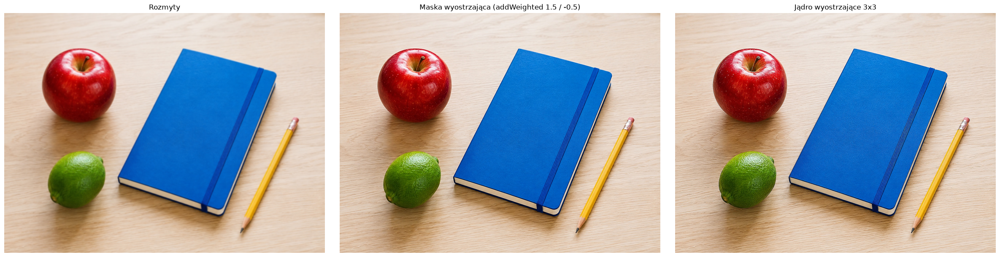

In [15]:
obraz_rgb = cv2.cvtColor(cv2.imread("obraz_testowy.jpg"), cv2.COLOR_BGR2RGB)

rozmyty = cv2.GaussianBlur(obraz_rgb, (9, 9), 0)
wyostrzony = cv2.addWeighted(obraz_rgb, 1.5, rozmyty, -0.5, 0)

jadro = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
wyostrzony_jadrem = cv2.filter2D(obraz_rgb, -1, jadro)

# Porównanie
plt.figure(figsize=(24, 6))

plt.subplot(1, 3, 1)
plt.imshow(rozmyty)
plt.title("Rozmyty")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(wyostrzony)
plt.title("Maska wyostrzająca (addWeighted 1.5 / -0.5)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(wyostrzony_jadrem)
plt.title("Jądro wyostrzające 3x3")
plt.axis("off")

plt.tight_layout()
plt.show()